In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import time

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("RetailIQ ML environment initialized!")

RetailIQ ML environment initialized!


In [2]:
DATA_DIR = Path("../dataset")

if not DATA_DIR.exists():
    DATA_DIR = Path("dataset")

train_df = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["Date"]
)

store_df = pd.read_csv(
    DATA_DIR / "store.csv"
)

test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    parse_dates=["Date"]
)

print("Datasets loaded successfully!")

print("Training:", train_df.shape)
print("Store:", store_df.shape)
print("Testing:", test_df.shape)

Datasets loaded successfully!
Training: (1017209, 9)
Store: (1115, 10)
Testing: (41088, 8)


In [3]:
train = train_df.merge(
    store_df,
    on="Store",
    how="left",
    validate="many_to_one"
)

test = test_df.merge(
    store_df,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

display(train.head())

Training dataset: (1017209, 18)
Testing dataset: (41088, 17)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [4]:
print("TRAINING DATA")
display(
    train.isnull().sum()[train.isnull().sum() > 0]
)

print("\nTESTING DATA")
display(
    test.isnull().sum()[test.isnull().sum() > 0]
)

TRAINING DATA


CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


TESTING DATA


Open                            11
CompetitionDistance             96
CompetitionOpenSinceMonth    15216
CompetitionOpenSinceYear     15216
Promo2SinceWeek              17232
Promo2SinceYear              17232
PromoInterval                17232
dtype: int64

In [5]:
# Investigate Promo2 missing values
print("PROMO2 DISTRIBUTION")
display(train["Promo2"].value_counts(dropna=False))

print("\nPROMO2 MISSING VALUES BY STATUS")
display(
    train.groupby("Promo2")[
        ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
    ].apply(lambda x: x.isnull().sum())
)

PROMO2 DISTRIBUTION


Promo2
1    509178
0    508031
Name: count, dtype: int64


PROMO2 MISSING VALUES BY STATUS


,Promo2SinceWeek,Promo2SinceYear,PromoInterval
Promo2,,,
0,508031,508031,508031
1,0,0,0


In [6]:
print("COMPETITION DISTANCE")
print("Missing:", train["CompetitionDistance"].isnull().sum())

print("\nCOMPETITION OPENING DATE")
display(
    train[
        ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]
    ].isnull().sum()
)

print("\nSTORES WITH MISSING COMPETITION DISTANCE")
display(
    store_df[store_df["CompetitionDistance"].isnull()]
)

COMPETITION DISTANCE
Missing: 2642

COMPETITION OPENING DATE


CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
dtype: int64


STORES WITH MISSING COMPETITION DISTANCE


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [7]:
missing_open = test[test["Open"].isnull()]

print("Rows with missing Open:", len(missing_open))
display(
    missing_open[
        ["Store", "DayOfWeek", "Date", "Promo", "StateHoliday", "SchoolHoliday"]
    ]
)

Rows with missing Open: 11


,Store,DayOfWeek,Date,Promo,StateHoliday,SchoolHoliday
479,622,4,2015-09-17,1,0,0
1335,622,3,2015-09-16,1,0,0
2191,622,2,2015-09-15,1,0,0
3047,622,1,2015-09-14,1,0,0
4759,622,6,2015-09-12,0,0,0
5615,622,5,2015-09-11,0,0,0
6471,622,4,2015-09-10,0,0,0
7327,622,3,2015-09-09,0,0,0
8183,622,2,2015-09-08,0,0,0
9039,622,1,2015-09-07,0,0,0


In [8]:
store_622 = train[train["Store"] == 622].copy()

print("Store 622 historical records:")
print("Total records:", len(store_622))

print("\nOpening status distribution:")
display(store_622["Open"].value_counts(dropna=False))

print("\nOpening status by weekday:")
display(
    store_622.groupby("DayOfWeek")["Open"]
    .agg(["count", "mean"])
)

Store 622 historical records:
Total records: 942

Opening status distribution:


Open
1    784
0    158
Name: count, dtype: int64


Opening status by weekday:


,count,mean
DayOfWeek,,
1,134,0.955224
2,135,0.992593
3,135,0.977778
4,135,0.940741
5,135,0.955556
6,134,1.000000
7,134,0.000000


In [9]:
print("Missing Open records:")
display(
    missing_open[
        ["Store", "DayOfWeek", "Date", "Promo"]
    ].sort_values("Date")
)

print("\nHistorical opening behaviour for Store 622:")
display(
    store_622.groupby("DayOfWeek")["Open"]
    .agg(lambda x: x.mode().iloc[0])
    .rename("Historical_Mode_Open")
)

Missing Open records:


,Store,DayOfWeek,Date,Promo
10751,622,6,2015-09-05,0
9039,622,1,2015-09-07,0
8183,622,2,2015-09-08,0
7327,622,3,2015-09-09,0
6471,622,4,2015-09-10,0
5615,622,5,2015-09-11,0
4759,622,6,2015-09-12,0
3047,622,1,2015-09-14,1
2191,622,2,2015-09-15,1
1335,622,3,2015-09-16,1



Historical opening behaviour for Store 622:


DayOfWeek
1    1
2    1
3    1
4    1
5    1
6    1
7    0
Name: Historical_Mode_Open, dtype: int64

In [10]:
# Work on independent copies
train_clean = train.copy()
test_clean = test.copy()

# 1. Competition distance: use training-store median
competition_median = store_df["CompetitionDistance"].median()

train_clean["CompetitionDistance"] = (
    train_clean["CompetitionDistance"].fillna(competition_median)
)

test_clean["CompetitionDistance"] = (
    test_clean["CompetitionDistance"].fillna(competition_median)
)

# 2. Competition opening information
competition_date_cols = [
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear"
]

for col in competition_date_cols:
    train_clean[col] = train_clean[col].fillna(0)
    test_clean[col] = test_clean[col].fillna(0)

# 3. Promo2 information
promo2_numeric_cols = [
    "Promo2SinceWeek",
    "Promo2SinceYear"
]

for col in promo2_numeric_cols:
    train_clean[col] = train_clean[col].fillna(0)
    test_clean[col] = test_clean[col].fillna(0)

train_clean["PromoInterval"] = train_clean["PromoInterval"].fillna("None")
test_clean["PromoInterval"] = test_clean["PromoInterval"].fillna("None")

# 4. Infer missing Open values for Store 622
store_622_modes = (
    train_clean[train_clean["Store"] == 622]
    .groupby("DayOfWeek")["Open"]
    .agg(lambda x: x.mode().iloc[0])
)

missing_mask = test_clean["Open"].isnull()

test_clean.loc[missing_mask, "Open"] = (
    test_clean.loc[missing_mask, "DayOfWeek"]
    .map(store_622_modes)
)

print("Cleaning completed!")

Cleaning completed!


In [11]:
print("TRAINING DATA - REMAINING MISSING VALUES")
display(train_clean.isnull().sum()[train_clean.isnull().sum() > 0])

print("\nTESTING DATA - REMAINING MISSING VALUES")
display(test_clean.isnull().sum()[test_clean.isnull().sum() > 0])

print("\nMissing Open values remaining:",
      test_clean["Open"].isnull().sum())

print("\nCleaned shapes:")
print("Training:", train_clean.shape)
print("Testing:", test_clean.shape)

TRAINING DATA - REMAINING MISSING VALUES


Series([], dtype: int64)


TESTING DATA - REMAINING MISSING VALUES


Series([], dtype: int64)


Missing Open values remaining: 0

Cleaned shapes:
Training: (1017209, 18)
Testing: (41088, 17)


In [12]:
# Extract date-based features

for dataset in [train_clean, test_clean]:

    dataset["Year"] = dataset["Date"].dt.year
    dataset["Month"] = dataset["Date"].dt.month
    dataset["Day"] = dataset["Date"].dt.day

    dataset["WeekOfYear"] = (
        dataset["Date"].dt.isocalendar().week.astype(int)
    )

    dataset["DayOfYear"] = dataset["Date"].dt.dayofyear

    # Calendar indicators
    dataset["IsWeekend"] = (
        dataset["DayOfWeek"].isin([6, 7]).astype(int)
    )

    dataset["IsMonthStart"] = (
        dataset["Date"].dt.is_month_start.astype(int)
    )

    dataset["IsMonthEnd"] = (
        dataset["Date"].dt.is_month_end.astype(int)
    )

print("Date features created successfully!")

display(
    train_clean[
        [
            "Date", "DayOfWeek", "Year", "Month",
            "Day", "WeekOfYear", "DayOfYear",
            "IsWeekend", "IsMonthStart", "IsMonthEnd"
        ]
    ].head(10)
)

Date features created successfully!


,Date,DayOfWeek,Year,Month,Day,WeekOfYear,DayOfYear,IsWeekend,IsMonthStart,IsMonthEnd
0,2015-07-31,5,2015,7,31,31,212,0,0,1
1,2015-07-31,5,2015,7,31,31,212,0,0,1
2,2015-07-31,5,2015,7,31,31,212,0,0,1
3,2015-07-31,5,2015,7,31,31,212,0,0,1
4,2015-07-31,5,2015,7,31,31,212,0,0,1
5,2015-07-31,5,2015,7,31,31,212,0,0,1
6,2015-07-31,5,2015,7,31,31,212,0,0,1
7,2015-07-31,5,2015,7,31,31,212,0,0,1
8,2015-07-31,5,2015,7,31,31,212,0,0,1
9,2015-07-31,5,2015,7,31,31,212,0,0,1


In [13]:
# Determine whether Promo2 is active on each date

for dataset in [train_clean, test_clean]:

    current_month = dataset["Date"].dt.month_name().str[:3]

    promo_months = dataset["PromoInterval"].str.split(",")

    dataset["IsPromo2Active"] = [
        int(
            promo2 == 1
            and year >= promo_year
            and month in interval
        )
        for promo2, year, promo_year, month, interval in zip(
            dataset["Promo2"],
            dataset["Year"],
            dataset["Promo2SinceYear"],
            current_month,
            promo_months
        )
    ]

print("Promotion features created successfully!")

display(
    train_clean[
        [
            "Date",
            "Promo",
            "Promo2",
            "Promo2SinceYear",
            "PromoInterval",
            "IsPromo2Active"
        ]
    ].head(15)
)

Promotion features created successfully!


,Date,Promo,Promo2,Promo2SinceYear,PromoInterval,IsPromo2Active
0,2015-07-31,1,0,0.0,None,0
1,2015-07-31,1,1,2010.0,"Jan,Apr,Jul,Oct",1
2,2015-07-31,1,1,2011.0,"Jan,Apr,Jul,Oct",1
3,2015-07-31,1,0,0.0,None,0
4,2015-07-31,1,0,0.0,None,0
5,2015-07-31,1,0,0.0,None,0
6,2015-07-31,1,0,0.0,None,0
7,2015-07-31,1,0,0.0,None,0
8,2015-07-31,1,0,0.0,None,0
9,2015-07-31,1,0,0.0,None,0


In [14]:
# Calculate competition duration

for dataset in [train_clean, test_clean]:

    dataset["CompetitionOpenMonths"] = (
        (dataset["Year"] - dataset["CompetitionOpenSinceYear"]) * 12
        + (dataset["Month"] - dataset["CompetitionOpenSinceMonth"])
    )

    # No recorded competition opening date
    no_competition_date = (
        (dataset["CompetitionOpenSinceYear"] == 0)
        | (dataset["CompetitionOpenSinceMonth"] == 0)
    )

    # Avoid negative durations and represent unavailable dates as zero
    dataset["CompetitionOpenMonths"] = (
        dataset["CompetitionOpenMonths"].clip(lower=0)
    )

    dataset.loc[
        no_competition_date,
        "CompetitionOpenMonths"
    ] = 0

print("Competition features created successfully!")

display(
    train_clean[
        [
            "Store",
            "Date",
            "CompetitionDistance",
            "CompetitionOpenSinceMonth",
            "CompetitionOpenSinceYear",
            "CompetitionOpenMonths"
        ]
    ].head(15)
)

Competition features created successfully!


,Store,Date,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,CompetitionOpenMonths
0,1,2015-07-31,1270.0,9.0,2008.0,82.0
1,2,2015-07-31,570.0,11.0,2007.0,92.0
2,3,2015-07-31,14130.0,12.0,2006.0,103.0
3,4,2015-07-31,620.0,9.0,2009.0,70.0
4,5,2015-07-31,29910.0,4.0,2015.0,3.0
5,6,2015-07-31,310.0,12.0,2013.0,19.0
6,7,2015-07-31,24000.0,4.0,2013.0,27.0
7,8,2015-07-31,7520.0,10.0,2014.0,9.0
8,9,2015-07-31,2030.0,8.0,2000.0,179.0
9,10,2015-07-31,3160.0,9.0,2009.0,70.0


In [15]:
# Identify whether competition opening information is available

for dataset in [train_clean, test_clean]:

    dataset["HasCompetitionDate"] = (
        (dataset["CompetitionOpenSinceMonth"] != 0) &
        (dataset["CompetitionOpenSinceYear"] != 0)
    ).astype(int)

print("Competition availability feature created!")

display(
    train_clean[
        [
            "Store",
            "CompetitionOpenMonths",
            "HasCompetitionDate"
        ]
    ].head(15)
)

print("\nCompetition date availability:")
display(train_clean["HasCompetitionDate"].value_counts())

Competition availability feature created!


,Store,CompetitionOpenMonths,HasCompetitionDate
0,1,82.0,1
1,2,92.0,1
2,3,103.0,1
3,4,70.0,1
4,5,3.0,1
5,6,19.0,1
6,7,27.0,1
7,8,9.0,1
8,9,179.0,1
9,10,70.0,1



Competition date availability:


HasCompetitionDate
1    693861
0    323348
Name: count, dtype: int64

In [16]:
# Create holiday-related features

for dataset in [train_clean, test_clean]:

    # Normalize StateHoliday values
    dataset["StateHoliday"] = (
        dataset["StateHoliday"].astype(str).str.lower()
    )

    # Identify state holidays (0 means no state holiday)
    dataset["IsStateHoliday"] = (
        dataset["StateHoliday"] != "0"
    ).astype(int)

    # Ensure school holiday is represented as an integer flag
    dataset["SchoolHoliday"] = (
        dataset["SchoolHoliday"].astype(int)
    )

print("Holiday features created successfully!")

display(
    train_clean[
        [
            "Date",
            "DayOfWeek",
            "StateHoliday",
            "IsStateHoliday",
            "SchoolHoliday"
        ]
    ].head(15)
)

print("\nState holiday distribution:")
display(train_clean["StateHoliday"].value_counts())

print("\nHoliday indicator distribution:")
display(train_clean["IsStateHoliday"].value_counts())

Holiday features created successfully!


,Date,DayOfWeek,StateHoliday,IsStateHoliday,SchoolHoliday
0,2015-07-31,5,0,0,1
1,2015-07-31,5,0,0,1
2,2015-07-31,5,0,0,1
3,2015-07-31,5,0,0,1
4,2015-07-31,5,0,0,1
5,2015-07-31,5,0,0,1
6,2015-07-31,5,0,0,1
7,2015-07-31,5,0,0,1
8,2015-07-31,5,0,0,1
9,2015-07-31,5,0,0,1



State holiday distribution:


StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64


Holiday indicator distribution:


IsStateHoliday
0    986159
1     31050
Name: count, dtype: int64

In [17]:
# Inspect categorical store features

categorical_columns = [
    "StoreType",
    "Assortment",
    "PromoInterval"
]

for col in categorical_columns:
    print(f"\n{col} distribution:")
    display(train_clean[col].value_counts(dropna=False))

print("\nStore type and assortment combinations:")
display(
    train_clean.groupby(
        ["StoreType", "Assortment"]
    )["Store"].nunique().unstack(fill_value=0)
)


StoreType distribution:


StoreType
a    551627
d    312912
c    136840
b     15830
Name: count, dtype: int64


Assortment distribution:


Assortment
a    537445
c    471470
b      8294
Name: count, dtype: int64


PromoInterval distribution:


PromoInterval
None                508031
Jan,Apr,Jul,Oct     293122
Feb,May,Aug,Nov     118596
Mar,Jun,Sept,Dec     97460
Name: count, dtype: int64


Store type and assortment combinations:


Assortment,a,b,c
StoreType,,,
a,381,0,221
b,7,9,1
c,77,0,71
d,128,0,220


In [18]:
# Define feature groups for model preparation

numeric_features = [
    "Store",
    "DayOfWeek",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "DayOfYear",
    "IsWeekend",
    "IsMonthStart",
    "IsMonthEnd",
    "Promo",
    "Promo2",
    "IsPromo2Active",
    "CompetitionDistance",
    "CompetitionOpenMonths",
    "HasCompetitionDate",
    "SchoolHoliday",
    "IsStateHoliday"
]

categorical_features = [
    "StoreType",
    "Assortment",
    "StateHoliday",
    "PromoInterval"
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumeric feature list:")
print(numeric_features)

print("\nCategorical feature list:")
print(categorical_features)

print("\nTotal features:", 
      len(numeric_features) + len(categorical_features))

Numeric features: 18
Categorical features: 4

Numeric feature list:
['Store', 'DayOfWeek', 'Year', 'Month', 'Day', 'WeekOfYear', 'DayOfYear', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'Promo', 'Promo2', 'IsPromo2Active', 'CompetitionDistance', 'CompetitionOpenMonths', 'HasCompetitionDate', 'SchoolHoliday', 'IsStateHoliday']

Categorical feature list:
['StoreType', 'Assortment', 'StateHoliday', 'PromoInterval']

Total features: 22


In [19]:
# Validate engineered datasets

print("TRAINING DATA VALIDATION")
print("Shape:", train_clean.shape)
print("Missing values:", train_clean.isnull().sum().sum())

print("\nTESTING DATA VALIDATION")
print("Shape:", test_clean.shape)
print("Missing values:", test_clean.isnull().sum().sum())

# Check feature availability
missing_train_features = [
    col for col in numeric_features + categorical_features
    if col not in train_clean.columns
]

missing_test_features = [
    col for col in numeric_features + categorical_features
    if col not in test_clean.columns
]

print("\nMissing training features:", missing_train_features)
print("Missing testing features:", missing_test_features)

# Check target columns
print("\nTarget availability:")
for target in ["Sales", "Customers", "Open"]:
    print(f"{target}: {target in train_clean.columns}")

TRAINING DATA VALIDATION
Shape: (1017209, 30)
Missing values: 0

TESTING DATA VALIDATION
Shape: (41088, 29)
Missing values: 0

Missing training features: []
Missing testing features: []

Target availability:
Sales: True
Customers: True
Open: True


In [20]:
# Chronological train-validation split

validation_start = (
    train_clean["Date"].max() - pd.Timedelta(weeks=6)
)

training_data = train_clean[
    train_clean["Date"] < validation_start
].copy()

validation_data = train_clean[
    train_clean["Date"] >= validation_start
].copy()

print("Chronological split completed!")

print("\nTraining period:")
print(training_data["Date"].min(), "to", training_data["Date"].max())

print("\nValidation period:")
print(validation_data["Date"].min(), "to", validation_data["Date"].max())

print("\nDataset sizes:")
print("Training:", training_data.shape)
print("Validation:", validation_data.shape)

print("\nTraining proportion:",
      round(len(training_data) / len(train_clean) * 100, 2), "%")

print("Validation proportion:",
      round(len(validation_data) / len(train_clean) * 100, 2), "%")

Chronological split completed!

Training period:
2013-01-01 00:00:00 to 2015-06-18 00:00:00

Validation period:
2015-06-19 00:00:00 to 2015-07-31 00:00:00

Dataset sizes:
Training: (969264, 30)
Validation: (47945, 30)

Training proportion: 95.29 %
Validation proportion: 4.71 %


In [21]:
# Correct feature types
numeric_features.remove("Store")
categorical_features.append("Store")

# Prepare sales modelling datasets
sales_train = training_data[training_data["Open"] == 1].copy()
sales_validation = validation_data[validation_data["Open"] == 1].copy()

# Input features and target
sales_feature_columns = numeric_features + categorical_features

X_train_sales = sales_train[sales_feature_columns]
y_train_sales = sales_train["Sales"]

X_val_sales = sales_validation[sales_feature_columns]
y_val_sales = sales_validation["Sales"]

print("Sales Forecasting dataset prepared!")

print("\nTraining records:", len(X_train_sales))
print("Validation records:", len(X_val_sales))

print("\nTraining target statistics:")
display(y_train_sales.describe())

print("\nValidation target statistics:")
display(y_val_sales.describe())

print("\nFeature count:", len(sales_feature_columns))

Sales Forecasting dataset prepared!

Training records: 802996
Validation records: 41396

Training target statistics:


count    802996.000000
mean       6953.470345
std        3107.272921
min           0.000000
25%        4854.000000
50%        6367.000000
75%        8359.000000
max       38722.000000
Name: Sales, dtype: float64


Validation target statistics:


count    41396.000000
mean      6995.162576
std       3044.048775
min        569.000000
25%       4943.000000
50%       6413.500000
75%       8383.250000
max      41551.000000
Name: Sales, dtype: float64


Feature count: 22


In [22]:
# Build preprocessing pipeline for Sales Forecasting

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
sales_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Sales preprocessing pipeline created successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Sales preprocessing pipeline created successfully!
Numerical features: 17
Categorical features: 5


In [23]:
# Configure HistGradientBoosting Regressor

from sklearn.ensemble import HistGradientBoostingRegressor

# Exclude high-cardinality Store identifier
sales_numeric_features = numeric_features.copy()

sales_categorical_features = [
    col for col in categorical_features if col != "Store"
]

sales_feature_columns = (
    sales_numeric_features + sales_categorical_features
)

# Rebuild preprocessing for the selected features
sales_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, sales_numeric_features),
        ("categorical", categorical_transformer, sales_categorical_features)
    ]
)

# Create model pipeline
sales_model = Pipeline(steps=[
    ("preprocessor", sales_preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

print("Sales Forecasting model configured!")
print("Algorithm: HistGradientBoosting Regressor")
print("Input features:", len(sales_feature_columns))

Sales Forecasting model configured!
Algorithm: HistGradientBoosting Regressor
Input features: 21


In [24]:
# Train the Sales Forecasting model

import time

# Configure dense categorical encoding for HistGradientBoosting
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Rebuild preprocessing pipeline
sales_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, sales_numeric_features),
        ("categorical", categorical_transformer, sales_categorical_features)
    ]
)

# Rebuild complete model pipeline
sales_model = Pipeline(steps=[
    ("preprocessor", sales_preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

# Train
print("Training Sales Forecasting model...")
start_time = time.time()

sales_model.fit(X_train_sales, y_train_sales)

training_time = time.time() - start_time

print("\nTraining completed successfully!")
print(f"Training time: {training_time:.2f} seconds")

Training Sales Forecasting model...

Training completed successfully!
Training time: 7.16 seconds


In [25]:
# Evaluate Sales Forecasting model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate predictions
y_pred_sales = sales_model.predict(X_val_sales)

# Calculate evaluation metrics
sales_mae = mean_absolute_error(y_val_sales, y_pred_sales)
sales_rmse = np.sqrt(mean_squared_error(y_val_sales, y_pred_sales))
sales_r2 = r2_score(y_val_sales, y_pred_sales)

print("SALES FORECASTING - MODEL EVALUATION")
print("-" * 45)

print(f"MAE:  €{sales_mae:,.2f}")
print(f"RMSE: €{sales_rmse:,.2f}")
print(f"R²:   {sales_r2:.4f}")

print("-" * 45)


SALES FORECASTING - MODEL EVALUATION
---------------------------------------------
MAE:  €1,365.65
RMSE: €1,884.81
R²:   0.6166
---------------------------------------------


In [26]:
# Calculate Mean Absolute Percentage Error

nonzero_mask = y_val_sales != 0

mape = np.mean(
    np.abs(
        (y_val_sales[nonzero_mask] -
         y_pred_sales[nonzero_mask]) /
        y_val_sales[nonzero_mask]
    )
) * 100

percentage_accuracy = 100 - mape

print(f"MAPE: {mape:.2f}%")
print(f"Approximate percentage accuracy: {percentage_accuracy:.2f}%")

MAPE: 22.73%
Approximate percentage accuracy: 77.27%


In [27]:
# Prepare data for Customer Footfall Forecasting

footfall_train = training_data[
    (training_data["Open"] == 1) &
    (training_data["Customers"] > 0)
].copy()

footfall_validation = validation_data[
    (validation_data["Open"] == 1) &
    (validation_data["Customers"] > 0)
].copy()

# Features: exclude Sales, Customers, and Open
footfall_feature_columns = [
    col for col in numeric_features + categorical_features
    if col not in ["Sales", "Customers", "Open"]
]

X_train_footfall = footfall_train[footfall_feature_columns]
y_train_footfall = footfall_train["Customers"]

X_val_footfall = footfall_validation[footfall_feature_columns]
y_val_footfall = footfall_validation["Customers"]

print("Training samples:", len(X_train_footfall))
print("Validation samples:", len(X_val_footfall))
print("Number of features:", len(footfall_feature_columns))

print("\nTraining target statistics:")
print(y_train_footfall.describe())

Training samples: 802944
Validation samples: 41396
Number of features: 22

Training target statistics:
count    802944.000000
mean        764.243107
std         401.913457
min           3.000000
25%         520.000000
50%         677.000000
75%         895.000000
max        7388.000000
Name: Customers, dtype: float64


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Numerical preprocessing
footfall_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
footfall_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
footfall_preprocessor = ColumnTransformer(transformers=[
    ("num", footfall_numeric_transformer, numeric_features),
    ("cat", footfall_categorical_transformer, categorical_features)
])

print("Footfall preprocessing pipeline created successfully.")

Footfall preprocessing pipeline created successfully.


In [29]:
footfall_model = Pipeline(steps=[
    ("preprocessor", footfall_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=4,
        random_state=RANDOM_STATE
    ))
])

start_time = time.time()

footfall_model.fit(X_train_footfall, y_train_footfall)

training_time = time.time() - start_time

print(f"Footfall model trained successfully in {training_time:.2f} seconds.")

Footfall model trained successfully in 238.55 seconds.


In [30]:
# Generate predictions
y_pred_footfall = footfall_model.predict(X_val_footfall)

# Calculate evaluation metrics
footfall_mae = mean_absolute_error(
    y_val_footfall, y_pred_footfall
)

footfall_rmse = np.sqrt(mean_squared_error(
    y_val_footfall, y_pred_footfall
))

footfall_r2 = r2_score(
    y_val_footfall, y_pred_footfall
)

footfall_mape = np.mean(
    np.abs(
        (y_val_footfall - y_pred_footfall) /
        y_val_footfall
    )
) * 100

print("CUSTOMER FOOTFALL MODEL EVALUATION")
print("-" * 40)
print(f"MAE:  {footfall_mae:.2f} customers")
print(f"RMSE: {footfall_rmse:.2f} customers")
print(f"R²:   {footfall_r2:.4f}")
print(f"MAPE: {footfall_mape:.2f}%")
print(f"Approximate percentage estimate: {100-footfall_mape:.2f}%")

CUSTOMER FOOTFALL MODEL EVALUATION
----------------------------------------
MAE:  152.10 customers
RMSE: 198.95 customers
R²:   0.7342
MAPE: 25.23%
Approximate percentage estimate: 74.77%


In [31]:
# Prepare Sales Performance Classification data

classification_train = training_data[
    (training_data["Open"] == 1) &
    (training_data["Sales"] > 0)
].copy()

classification_validation = validation_data[
    (validation_data["Open"] == 1) &
    (validation_data["Sales"] > 0)
].copy()

# Calculate category thresholds using training data only
low_threshold = classification_train["Sales"].quantile(0.33)
high_threshold = classification_train["Sales"].quantile(0.66)

# Assign sales performance categories
def classify_sales(sales):
    if sales <= low_threshold:
        return "Low"
    elif sales <= high_threshold:
        return "Medium"
    else:
        return "High"

classification_train["SalesCategory"] = (
    classification_train["Sales"].apply(classify_sales)
)

classification_validation["SalesCategory"] = (
    classification_validation["Sales"].apply(classify_sales)
)

# Prepare features (exclude Store ID, Sales, Customers and Open)
classification_feature_columns = [
    col for col in numeric_features + categorical_features
    if col not in ["Store", "Sales", "Customers", "Open"]
]

X_train_classification = classification_train[
    classification_feature_columns
]

y_train_classification = classification_train["SalesCategory"]

X_val_classification = classification_validation[
    classification_feature_columns
]

y_val_classification = classification_validation["SalesCategory"]

print("Training samples:", len(X_train_classification))
print("Validation samples:", len(X_val_classification))
print("Number of features:", len(classification_feature_columns))

print("\nSales category thresholds:")
print(f"Low: Up to {low_threshold:.2f}")
print(f"Medium: {low_threshold:.2f} to {high_threshold:.2f}")
print(f"High: Above {high_threshold:.2f}")

print("\nTraining category distribution:")
print(y_train_classification.value_counts())

print("\nValidation category distribution:")
print(y_val_classification.value_counts())

Training samples: 802942
Validation samples: 41396
Number of features: 21

Sales category thresholds:
Low: Up to 5340.00
Medium: 5340.00 to 7522.00
High: Above 7522.00

Training category distribution:
SalesCategory
High      272994
Low       265022
Medium    264926
Name: count, dtype: int64

Validation category distribution:
SalesCategory
High      14320
Medium    13909
Low       13167
Name: count, dtype: int64


In [32]:
from sklearn.ensemble import RandomForestClassifier

# Numerical preprocessing
classification_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
classification_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
classification_preprocessor = ColumnTransformer(transformers=[
    ("num", classification_numeric_transformer, numeric_features),
    ("cat", classification_categorical_transformer, categorical_features)
])

print("Classification preprocessing pipeline created successfully.")

Classification preprocessing pipeline created successfully.


In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Separate numerical and categorical features
hgb_numeric_features = numeric_features.copy()

hgb_categorical_features = [
    col for col in categorical_features
    if col != "Store"
]

# Numerical preprocessing
hgb_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
hgb_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
classification_preprocessor = ColumnTransformer(
    transformers=[
        ("num", hgb_numeric_transformer, hgb_numeric_features),
        ("cat", hgb_categorical_transformer, hgb_categorical_features)
    ]
)

classification_feature_columns = (
    hgb_numeric_features + hgb_categorical_features
)

X_train_classification = classification_train[
    classification_feature_columns
]

X_val_classification = classification_validation[
    classification_feature_columns
]

print("HistGradientBoosting preprocessing pipeline created.")
print("Total features:", len(classification_feature_columns))

HistGradientBoosting preprocessing pipeline created.
Total features: 21


In [34]:
classification_model = Pipeline(steps=[
    ("preprocessor", classification_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

# Train the classifier
start_time = time.time()

classification_model.fit(
    X_train_classification,
    y_train_classification
)

training_time = time.time() - start_time

print(
    f"HistGradientBoosting classifier trained "
    f"successfully in {training_time:.2f} seconds."
)

HistGradientBoosting classifier trained successfully in 18.41 seconds.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred_classification = classification_model.predict(
    X_val_classification
)

# Calculate metrics
classification_accuracy = accuracy_score(
    y_val_classification, y_pred_classification
)

classification_precision = precision_score(
    y_val_classification, y_pred_classification,
    average="weighted"
)

classification_recall = recall_score(
    y_val_classification, y_pred_classification,
    average="weighted"
)

classification_f1 = f1_score(
    y_val_classification, y_pred_classification,
    average="weighted"
)

print("HISTGRADIENTBOOSTING CLASSIFICATION EVALUATION")
print("-" * 50)
print(f"Accuracy:  {classification_accuracy * 100:.2f}%")
print(f"Precision: {classification_precision * 100:.2f}%")
print(f"Recall:    {classification_recall * 100:.2f}%")
print(f"F1-Score:  {classification_f1 * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(
    y_val_classification,
    y_pred_classification
))

HISTGRADIENTBOOSTING CLASSIFICATION EVALUATION
--------------------------------------------------
Accuracy:  72.28%
Precision: 72.26%
Recall:    72.28%
F1-Score:  72.17%

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.74      0.82      0.78     14320
         Low       0.79      0.73      0.76     13167
      Medium       0.64      0.62      0.63     13909

    accuracy                           0.72     41396
   macro avg       0.72      0.72      0.72     41396
weighted avg       0.72      0.72      0.72     41396



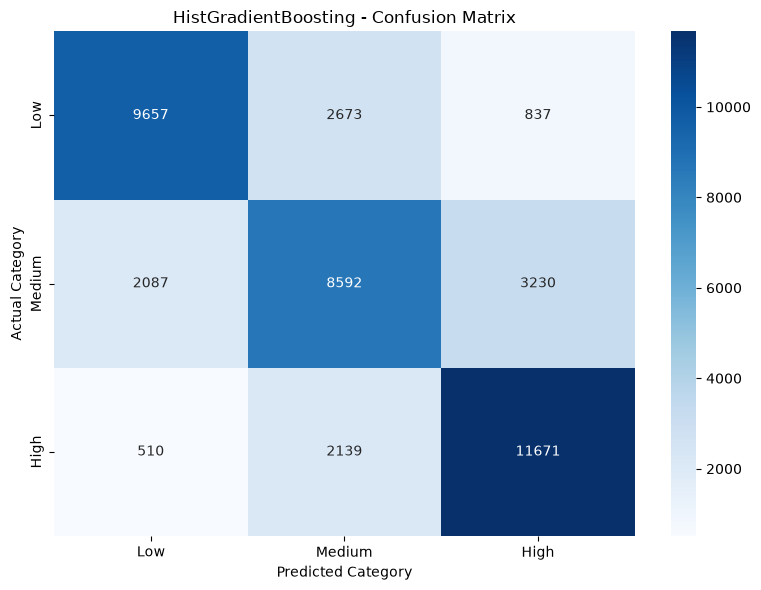

In [36]:
cm = confusion_matrix(
    y_val_classification,
    y_pred_classification,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("HistGradientBoosting - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [37]:
# Prepare store-level data for segmentation

store_segmentation = train_clean[
    train_clean["Open"] == 1
].groupby("Store").agg(
    AverageSales=("Sales", "mean"),
    AverageCustomers=("Customers", "mean"),
    MedianSales=("Sales", "median"),
    SalesStd=("Sales", "std"),
    AveragePromoSales=("Sales", lambda x: x.mean()),
    PromoDays=("Promo", "sum"),
    OperatingDays=("Open", "count"),
    CompetitionDistance=("CompetitionDistance", "first"),
    StoreType=("StoreType", "first"),
    Assortment=("Assortment", "first"),
    Promo2=("Promo2", "first")
).reset_index()

print("Store segmentation dataset created.")
print("Number of stores:", len(store_segmentation))
print("Number of features:", store_segmentation.shape[1] - 1)

display(store_segmentation.head())

Store segmentation dataset created.
Number of stores: 1115
Number of features: 11


,Store,AverageSales,AverageCustomers,MedianSales,SalesStd,AveragePromoSales,PromoDays,OperatingDays,CompetitionDistance,StoreType,Assortment,Promo2
0,1,4759.096031,564.049936,4647.0,1012.106393,4759.096031,350,781,1270.0,c,a,0
1,2,4953.900510,583.998724,4783.0,1610.149102,4953.900510,354,784,570.0,a,a,1
2,3,6942.568678,750.077022,6619.0,2193.383804,6942.568678,350,779,14130.0,a,a,1
3,4,9638.401786,1321.752551,9430.5,1936.031881,9638.401786,353,784,620.0,c,c,0
4,5,4676.274711,537.340180,4616.0,1765.745628,4676.274711,351,779,29910.0,a,a,0


In [38]:
# Calculate average sales during promotional days
promo_sales = (
    train_clean[
        (train_clean["Open"] == 1) &
        (train_clean["Promo"] == 1)
    ]
    .groupby("Store")["Sales"]
    .mean()
)

# Calculate average sales during non-promotional days
nonpromo_sales = (
    train_clean[
        (train_clean["Open"] == 1) &
        (train_clean["Promo"] == 0)
    ]
    .groupby("Store")["Sales"]
    .mean()
)

# Add promotional performance to segmentation dataset
store_segmentation["AveragePromoSales"] = (
    store_segmentation["Store"].map(promo_sales)
)

store_segmentation["AverageNonPromoSales"] = (
    store_segmentation["Store"].map(nonpromo_sales)
)

# Calculate promotional sales lift
store_segmentation["PromoSalesLift"] = (
    store_segmentation["AveragePromoSales"] -
    store_segmentation["AverageNonPromoSales"]
)

print("Promotional performance features calculated.")

display(store_segmentation[
    ["Store", "AverageSales", "AveragePromoSales",
     "AverageNonPromoSales", "PromoSalesLift"]
].head())

Promotional performance features calculated.


,Store,AverageSales,AveragePromoSales,AverageNonPromoSales,PromoSalesLift
0,1,4759.096031,5300.111429,4319.756381,980.355048
1,2,4953.900510,6277.440678,3864.288372,2413.152306
2,3,6942.568678,8854.628571,5382.613054,3472.015518
3,4,9638.401786,10576.158640,8870.354988,1705.803652
4,5,4676.274711,6096.683761,3511.406542,2585.277219


In [39]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Select numerical features
segmentation_numeric_features = [
    "AverageSales",
    "AverageCustomers",
    "MedianSales",
    "SalesStd",
    "PromoDays",
    "OperatingDays",
    "CompetitionDistance",
    "AveragePromoSales",
    "AverageNonPromoSales",
    "PromoSalesLift"
]

# Select categorical features
segmentation_categorical_features = [
    "StoreType",
    "Assortment",
    "Promo2"
]

# Numerical preprocessing
segmentation_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
segmentation_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
segmentation_preprocessor = ColumnTransformer(
    transformers=[
        ("num", segmentation_numeric_transformer,
         segmentation_numeric_features),
        ("cat", segmentation_categorical_transformer,
         segmentation_categorical_features)
    ]
)

# Prepare input data
X_segmentation = store_segmentation[
    segmentation_numeric_features +
    segmentation_categorical_features
]

# Transform features
X_segmentation_scaled = segmentation_preprocessor.fit_transform(
    X_segmentation
)

print("Segmentation preprocessing completed.")
print("Original feature count:", X_segmentation.shape[1])
print("Processed feature count:", X_segmentation_scaled.shape[1])
print("Processed dataset shape:", X_segmentation_scaled.shape)

Segmentation preprocessing completed.
Original feature count: 13
Processed feature count: 19
Processed dataset shape: (1115, 19)


In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
cluster_range = range(2, 11)

inertia_scores = []
silhouette_scores = []

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_segmentation_scaled)

    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_segmentation_scaled, cluster_labels)
    )

    print(
        f"K={k} | Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={silhouette_scores[-1]:.4f}"
    )

K=2 | Inertia=9272.07 | Silhouette=0.3057
K=3 | Inertia=7399.59 | Silhouette=0.3144
K=4 | Inertia=6176.27 | Silhouette=0.2597
K=5 | Inertia=5579.71 | Silhouette=0.2095
K=6 | Inertia=5096.69 | Silhouette=0.2163
K=7 | Inertia=4781.92 | Silhouette=0.2138
K=8 | Inertia=4545.08 | Silhouette=0.1992
K=9 | Inertia=4313.00 | Silhouette=0.1852
K=10 | Inertia=4119.83 | Silhouette=0.1911


In [41]:
# Train final K-Means model with 3 clusters

kmeans_model = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=20
)

store_segmentation["Cluster"] = kmeans_model.fit_predict(
    X_segmentation_scaled
)

print("K-Means clustering completed successfully.")

print("\nStore distribution across clusters:")
print(store_segmentation["Cluster"].value_counts().sort_index())

print("\nCluster proportions:")
print(
    (store_segmentation["Cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

K-Means clustering completed successfully.

Store distribution across clusters:
Cluster
0    692
1    174
2    249
Name: count, dtype: int64

Cluster proportions:
Cluster
0    62.06
1    15.61
2    22.33
Name: proportion, dtype: float64


In [42]:
# Analyse average characteristics of each cluster

cluster_profile = store_segmentation.groupby("Cluster").agg(
    StoreCount=("Store", "count"),
    AverageSales=("AverageSales", "mean"),
    AverageCustomers=("AverageCustomers", "mean"),
    MedianSales=("MedianSales", "mean"),
    SalesVariability=("SalesStd", "mean"),
    AveragePromoSales=("AveragePromoSales", "mean"),
    AverageNonPromoSales=("AverageNonPromoSales", "mean"),
    AveragePromoLift=("PromoSalesLift", "mean"),
    CompetitionDistance=("CompetitionDistance", "mean")
).round(2)

display(cluster_profile)

,StoreCount,AverageSales,AverageCustomers,MedianSales,SalesVariability,AveragePromoSales,AverageNonPromoSales,AveragePromoLift,CompetitionDistance
Cluster,,,,,,,,,
0,692,5937.10,648.70,5714.30,1639.90,7079.93,5006.65,2073.27,5373.06
1,174,6319.84,603.48,6100.35,1543.38,7319.61,5531.99,1787.62,4705.26
2,249,10134.61,1154.10,9744.82,2631.29,11951.21,8669.32,3281.89,5945.20


In [43]:
# Calculate additional store-level business KPIs

store_segmentation["SalesPerCustomer"] = (
    store_segmentation["AverageSales"] /
    store_segmentation["AverageCustomers"]
)

store_segmentation["PromoLiftPercentage"] = (
    store_segmentation["PromoSalesLift"] /
    store_segmentation["AverageNonPromoSales"]
) * 100

# Summarise KPIs by cluster
cluster_kpi = store_segmentation.groupby("Cluster").agg(
    StoreCount=("Store", "count"),
    AverageSales=("AverageSales", "mean"),
    AverageCustomers=("AverageCustomers", "mean"),
    SalesPerCustomer=("SalesPerCustomer", "mean"),
    PromoLift=("PromoSalesLift", "mean"),
    PromoLiftPercentage=("PromoLiftPercentage", "mean")
).round(2)

display(cluster_kpi)

,StoreCount,AverageSales,AverageCustomers,SalesPerCustomer,PromoLift,PromoLiftPercentage
Cluster,,,,,,
0,692,5937.10,648.70,9.45,2073.27,43.37
1,174,6319.84,603.48,10.79,1787.62,34.54
2,249,10134.61,1154.10,9.39,3281.89,40.85


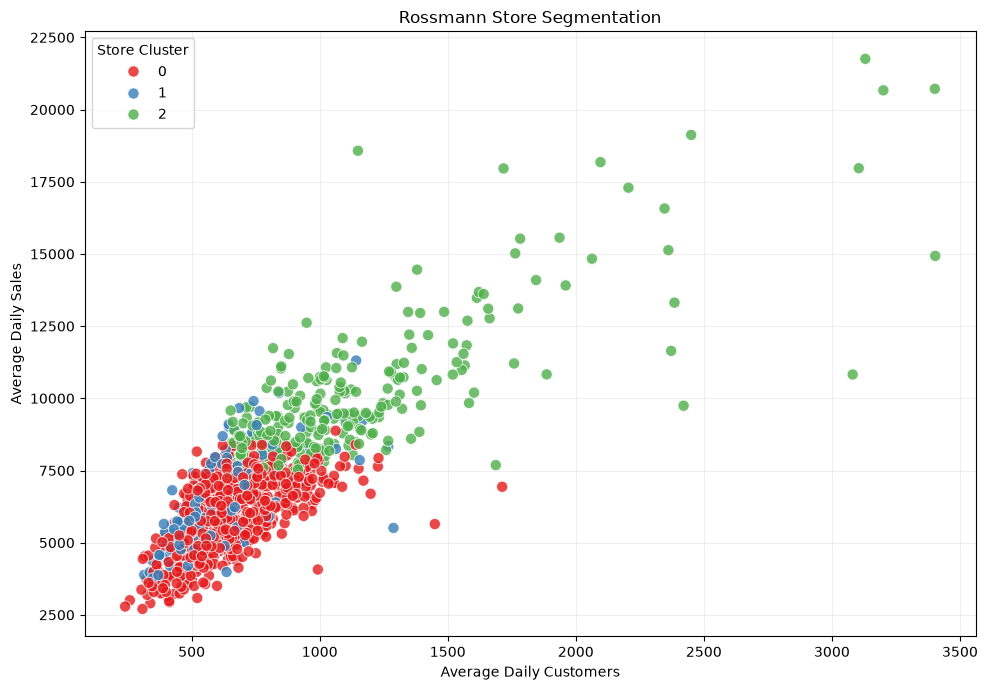

In [44]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=store_segmentation,
    x="AverageCustomers",
    y="AverageSales",
    hue="Cluster",
    palette="Set1",
    s=65,
    alpha=0.8
)

plt.title("Rossmann Store Segmentation")
plt.xlabel("Average Daily Customers")
plt.ylabel("Average Daily Sales")
plt.legend(title="Store Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [45]:
from pathlib import Path

# Resolve the project root (parent of notebooks)
PROJECT_ROOT = Path.cwd().parent

MODELS_DIR = PROJECT_ROOT / "models"

model_directories = {
    "sales": MODELS_DIR / "model_1_sales_forecasting",
    "footfall": MODELS_DIR / "model_2_customer_footfall",
    "classification": MODELS_DIR / "model_3_sales_classification",
    "segmentation": MODELS_DIR / "model_4_store_segmentation"
}

# Create directories
for directory in model_directories.values():
    directory.mkdir(parents=True, exist_ok=True)

# Model 1
joblib.dump(
    sales_model,
    model_directories["sales"] / "sales_forecasting_model.pkl"
)

# Model 2
joblib.dump(
    footfall_model,
    model_directories["footfall"] / "customer_footfall_model.pkl"
)

# Model 3
joblib.dump(
    classification_model,
    model_directories["classification"] / "sales_classification_model.pkl"
)

# Model 4
joblib.dump(
    kmeans_model,
    model_directories["segmentation"] / "store_segmentation_model.pkl"
)

joblib.dump(
    segmentation_preprocessor,
    model_directories["segmentation"] / "store_segmentation_preprocessor.pkl"
)

store_segmentation.to_csv(
    model_directories["segmentation"] / "store_segmentation_results.csv",
    index=False
)

print("All four models saved successfully!")
print("Models directory:", MODELS_DIR.resolve())

All four models saved successfully!
Models directory: C:\Users\Akshat\Desktop\Over Here\Projects\RetaillQ\models


In [46]:
# Prepare Store Closure Prediction data

closure_train = training_data.copy()
closure_validation = validation_data.copy()

# Select features available before the store's opening status is known
closure_feature_columns = [
    col for col in numeric_features + categorical_features
    if col not in ["Sales", "Customers", "Open"]
]

# Prepare training and validation data
X_train_closure = closure_train[closure_feature_columns]
y_train_closure = closure_train["Open"].astype(int)

X_val_closure = closure_validation[closure_feature_columns]
y_val_closure = closure_validation["Open"].astype(int)

print("Training samples:", len(X_train_closure))
print("Validation samples:", len(X_val_closure))
print("Number of features:", len(closure_feature_columns))

print("\nTraining target distribution:")
print(y_train_closure.value_counts())

print("\nValidation target distribution:")
print(y_val_closure.value_counts())

print("\nTraining class percentages:")
print((y_train_closure.value_counts(normalize=True) * 100).round(2))

Training samples: 969264
Validation samples: 47945
Number of features: 22

Training target distribution:
Open
1    802996
0    166268
Name: count, dtype: int64

Validation target distribution:
Open
1    41396
0     6549
Name: count, dtype: int64

Training class percentages:
Open
1    82.85
0    17.15
Name: proportion, dtype: float64


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

# Numerical preprocessing
closure_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
closure_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
closure_preprocessor = ColumnTransformer(transformers=[
    ("num", closure_numeric_transformer, numeric_features),
    ("cat", closure_categorical_transformer, categorical_features)
])

print("Store closure preprocessing pipeline created successfully.")

Store closure preprocessing pipeline created successfully.


In [48]:
closure_model = Pipeline(steps=[
    ("preprocessor", closure_preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Train the model
start_time = time.time()

closure_model.fit(
    X_train_closure,
    y_train_closure
)

training_time = time.time() - start_time

print(
    f"Store closure model trained successfully "
    f"in {training_time:.2f} seconds."
)

Store closure model trained successfully in 11.74 seconds.


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred_closure = closure_model.predict(X_val_closure)

# Calculate metrics
closure_accuracy = accuracy_score(
    y_val_closure, y_pred_closure
)

closure_precision = precision_score(
    y_val_closure, y_pred_closure,
    average="weighted"
)

closure_recall = recall_score(
    y_val_closure, y_pred_closure,
    average="weighted"
)

closure_f1 = f1_score(
    y_val_closure, y_pred_closure,
    average="weighted"
)

print("STORE CLOSURE PREDICTION EVALUATION")
print("-" * 50)
print(f"Accuracy:  {closure_accuracy * 100:.2f}%")
print(f"Precision: {closure_precision * 100:.2f}%")
print(f"Recall:    {closure_recall * 100:.2f}%")
print(f"F1-Score:  {closure_f1 * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(
    y_val_closure,
    y_pred_closure,
    target_names=["Closed", "Open"]
))

STORE CLOSURE PREDICTION EVALUATION
--------------------------------------------------
Accuracy:  99.80%
Precision: 99.80%
Recall:    99.80%
F1-Score:  99.80%

Detailed Classification Report:
              precision    recall  f1-score   support

      Closed       0.99      0.99      0.99      6549
        Open       1.00      1.00      1.00     41396

    accuracy                           1.00     47945
   macro avg       1.00      1.00      1.00     47945
weighted avg       1.00      1.00      1.00     47945



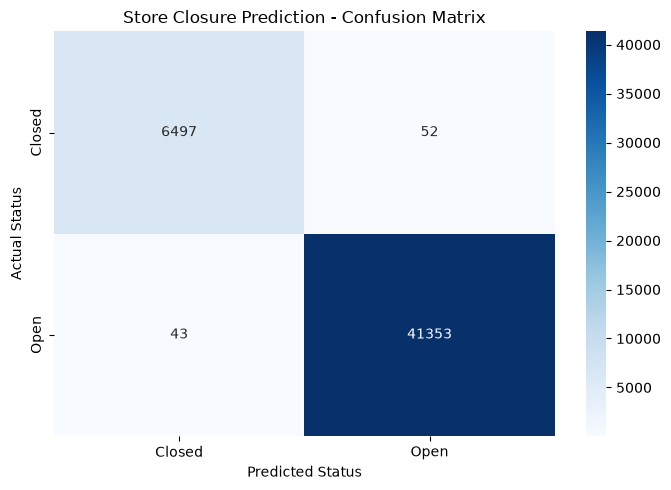

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

closure_cm = confusion_matrix(
    y_val_closure,
    y_pred_closure
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    closure_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Closed", "Open"],
    yticklabels=["Closed", "Open"]
)

plt.title("Store Closure Prediction - Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()

In [51]:
# Create Model 5 directory
closure_model_dir = MODELS_DIR / "model_5_store_closure"
closure_model_dir.mkdir(parents=True, exist_ok=True)

# Save complete pipeline
joblib.dump(
    closure_model,
    closure_model_dir / "store_closure_model.pkl"
)

print("Store closure model saved successfully!")
print(f"Location: {closure_model_dir}")

Store closure model saved successfully!
Location: c:\Users\Akshat\Desktop\Over Here\Projects\RetaillQ\models\model_5_store_closure
